# 06 — GRPO with outcome reward (Exp 4) from the RFT-SFT model

- **Start:** 05's RFT-SFT model (GSM8K 49.4, SVAMP 61.9, val 66.6).
- **Reward:** 1 if the answer ends with a correct `#### <n>`, else 0.
- **GPUs:** GPU 0 = vLLM server (generates answers), GPU 1 = TRL `GRPOTrainer` (training). TRL syncs weights to vLLM every step.
- **Inputs (*Add Input*):** `00_data`, `04_rft_data`, `05_sft_with_rft`.
- Run `DEBUG = True` first (3 steps), then `False`.

In [1]:
DEBUG = False

## Install
`trl[vllm]` installs vLLM, which **replaces Kaggle's torch** with the torch its wheel was built for (CUDA 12.9).
Lines like `ERROR: pip's dependency resolver ... numba / cuda-core / opentelemetry` are **warnings** about preinstalled
packages this notebook never uses (cudf, cuml, ydata-profiling, google-adk) — ignore them.
Run this cell **before anything imports torch**. If torch was already imported, restart the kernel (Run → Restart) and skip this cell.
The check runs in a separate process so it doesn't load torch here (the next cell must set `CUDA_VISIBLE_DEVICES` first).
Once a run works, pin the printed versions here (e.g. `trl==X vllm==Y`) so 07 uses the exact same stack.

In [2]:
!pip install -q "trl[vllm]"
!python -c "import torch, transformers, trl, vllm; print('torch', torch.__version__, '| cuda', torch.version.cuda, '| transformers', transformers.__version__, '| trl', trl.__version__, '| vllm', vllm.__version__); print([(torch.cuda.get_device_name(i), torch.cuda.get_device_capability(i)) for i in range(torch.cuda.device_count())])"

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
ydata-profiling 4.18.4 requires numba<0.63,>=0.60, but you have numba 0.65.0 which is incompatible.
numba-cuda 0.28.2 requires cuda-core<1.0.0,>=0.5.1, but you have cuda-core 1.3.0 which is incompatible.
cuml-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
cudf-cu13 26.6.0 requires numba<0.65.0,>=0.60.0, but you have numba 0.65.0 which is incompatible.
gradio 6.30.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.
google-adk 2.7.1 requires opentelemetry-api<=1.42.1,>=1.39, but you have opentelemetry-api 1.45.2 which is incompatible.
google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.
torch 2.13.0+cu130 | cuda 13.0 | transformers 5.19.0 | trl 1.17.1 | vllm 0.32.0
[('Tesla T4

## Config

In [3]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"      # this notebook trains on GPU 1; the vLLM server gets GPU 0 (set below)
# Kaggle 2xT4: NCCL direct GPU-to-GPU copy (P2P) hangs -> the trainer->vLLM weight sync would freeze after step 0.
# Set before the server starts so both sides of the NCCL link use it (same fix as 02 / 05).
os.environ.update(NCCL_P2P_DISABLE="1", NCCL_IB_DISABLE="1", TOKENIZERS_PARALLELISM="false")

import json, re, subprocess, time, urllib.request
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

DATA_DIR = Path("/kaggle/input/notebooks/tensorpanda231/00-data-math-reasoning/data")
RFT_DIR = Path("/kaggle/input/notebooks/tensorpanda231/04-rft-data/exp4_rft_data")
SFT_DIR = Path("/kaggle/input/notebooks/tensorpanda231/05-sft-with-rft-qwen-05b/exp5_sft_rft_0.5b")
OUT_DIR = Path("/kaggle/working/exp6_grpo_0.5b" + ("_debug" if DEBUG else ""))
OUT_DIR.mkdir(parents=True, exist_ok=True)

CFG = dict(
    model_dir=str(SFT_DIR / "model"), seed=42,
    instruction="Solve the problem step by step. End your answer with a final line of the form '#### <number>'.",
    # GRPO ("normal" GRPO; 07_dr_grpo changes only loss_type="dr_grpo", scale_rewards="none")
    loss_type="grpo", scale_rewards="group", beta=0.04, num_generations=8,
    per_device_bs=4, grad_accum=64,            # 256 answers = 32 prompts x 8 per optimizer step
    lr=1e-6, max_steps=400, train_hours=9.5, max_completion_length=512,
    eval_every=50, n_val=500, eval_batch=64,
)
if DEBUG:
    CFG.update(max_steps=3, grad_accum=4, eval_every=2, n_val=16)
(OUT_DIR / "config.json").write_text(json.dumps(CFG, indent=2))

515

## Reward
TRL calls it with `completions` (each is `[{"role": "assistant", "content": text}]`) and `gold` (the dataset column,
aligned with `completions`). Return one float per completion: **1.0 if `has_format` and `is_correct(pred, gold)`, else 0.0**.
`extract_pred` / `is_correct` are the shared ones from 01 / 05.

In [4]:
NUM_RE = re.compile(r"-?\d[\d,]*(?:\.\d+)?")

def extract_pred(text):
    """Number after the last '####' -> (pred, True); else the last number -> (pred, False)."""
    if "####" in text:
        nums = NUM_RE.findall(text.split("####")[-1])
        if nums:
            return nums[0].replace(",", ""), True
    nums = NUM_RE.findall(text)
    return (nums[-1].replace(",", ""), False) if nums else (None, False)

def is_correct(pred, gold):
    try:
        return pred is not None and abs(float(pred) - float(gold)) < 1e-6
    except ValueError:
        return False

def correctness_reward(completions, gold, **kwargs):
    """1.0 if the answer has a '####' line and its number is correct, else 0.0 (one float per completion)."""
    rewards = []
    for completion, g in zip(completions, gold):
        pred, has_format = extract_pred(completion[0]["content"])
        rewards.append(float(has_format and is_correct(pred, g)))
    return rewards

In [5]:
cases = [("3 + 4 = 7\n#### 7", "7", 1.0), ("so 1,000 total\n#### 1,000", "1000", 1.0), ("#### -3", "-3", 1.0),
         ("#### 2.50", "2.5", 1.0), ("#### 8", "7", 0.0), ("The answer is 7", "7", 0.0), ("\\boxed{7}", "7", 0.0),
         ("#### 5\nwait\n#### 7", "7", 1.0), ("", "7", 0.0)]
got = correctness_reward([[{"role": "assistant", "content": t}] for t, _, _ in cases], [g for _, g, _ in cases])
for (t, g, want), r in zip(cases, got):
    assert float(r) == want, f"{t!r} gold={g}: got {r}, want {want}"
print("reward tests passed")

reward tests passed


## Prompts
GSM8K train, minus problems the base model already solved 8/8 in 04 (they give no gradient).

In [6]:
def prompt_msgs(q):
    return [{"role": "user", "content": f"{q}\n\n{CFG['instruction']}"}]

train_df = pd.read_json(DATA_DIR / "gsm8k_train.jsonl", lines=True, dtype={"gold": str})
n_correct = pd.read_csv(RFT_DIR / "problem_stats_train.csv", index_col=0)["n_correct"].to_numpy()
assert len(n_correct) == len(train_df)
train_df = train_df[n_correct < 8].head(16 if DEBUG else None)
val_df = pd.read_json(DATA_DIR / "gsm8k_val.jsonl", lines=True, dtype={"gold": str}).head(CFG["n_val"])

from datasets import Dataset
train_ds = Dataset.from_list([{"prompt": prompt_msgs(q), "gold": g} for q, g in zip(train_df.question, train_df.gold)])
print(f"{len(train_ds)} prompts | {len(val_df)} val problems")

6279 prompts | 500 val problems


## vLLM server on GPU 0
Flags from the TRL vLLM docs; `--dtype half` (T4 has no bf16), `--generation-config vllm` (ignore Qwen's sampling defaults).

In [7]:
server = subprocess.Popen(
    ["vllm", "serve", CFG["model_dir"], "--port", "8000", "--dtype", "half", "--max-model-len", "1024",
     "--gpu-memory-utilization", "0.85", "--generation-config", "vllm", "--weight-transfer-config", '{"backend": "nccl"}',
     "--logprobs-mode", "processed_logprobs", "--max-logprobs", "-1"],
    stdout=open(OUT_DIR / "vllm.log", "w"), stderr=subprocess.STDOUT,
    env={**os.environ, "CUDA_VISIBLE_DEVICES": "0", "VLLM_SERVER_DEV_MODE": "1"})

for _ in range(90):                                   # wait up to 15 min
    try:
        urllib.request.urlopen("http://localhost:8000/health", timeout=5)
        print("vLLM server up")
        break
    except Exception:
        if server.poll() is not None:
            break
        time.sleep(10)
else:
    server.kill()
if server.poll() is not None:
    print((OUT_DIR / "vllm.log").read_text()[-4000:])
    raise RuntimeError("vLLM server failed, log above")

vLLM server up


## Train
`ValCallback`: greedy val accuracy at step 0 and every `eval_every` steps (same generation as 01 / 05), saves the best model
to `OUT_DIR/model`, and stops training after `train_hours`.

In [8]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer, TrainerCallback
from trl import GRPOConfig, GRPOTrainer

tok = AutoTokenizer.from_pretrained(CFG["model_dir"])
gen_tok = AutoTokenizer.from_pretrained(CFG["model_dir"], padding_side="left")
model = AutoModelForCausalLM.from_pretrained(CFG["model_dir"], dtype=torch.float32)   # fp32 master weights, fp16 AMP


@torch.inference_mode()
def generate(model, questions, tok=gen_tok):
    """Greedy answers, same settings as every earlier eval."""
    answers = []
    for i in range(0, len(questions), CFG["eval_batch"]):
        texts = [tok.apply_chat_template(prompt_msgs(q), tokenize=False, add_generation_prompt=True)
                 for q in questions[i:i + CFG["eval_batch"]]]
        enc = tok(texts, return_tensors="pt", padding=True).to(model.device)
        with torch.autocast("cuda", dtype=torch.float16):
            out = model.generate(**enc, do_sample=False, temperature=None, top_p=None, top_k=None,
                                 max_new_tokens=512, pad_token_id=tok.pad_token_id)
        answers += tok.batch_decode(out[:, enc.input_ids.shape[1]:], skip_special_tokens=True)
    return answers


class ValCallback(TrainerCallback):
    def __init__(self):
        self.history, self.best, self.best_step, self.t0 = [], -1.0, None, time.time()

    def evaluate(self, model, step):
        model.eval()
        answers = generate(model, list(val_df.question))
        model.train()
        acc = sum(is_correct(extract_pred(a)[0], g) for a, g in zip(answers, val_df.gold)) / len(val_df)
        self.history.append(dict(step=step, val_accuracy=acc))
        if acc > self.best:
            self.best, self.best_step = acc, step
            model.save_pretrained(OUT_DIR / "model", state_dict={k: v.half() for k, v in model.state_dict().items()})
            tok.save_pretrained(OUT_DIR / "model")
        print(f"EVAL step {step}: val acc {acc:.4f} | best {self.best:.4f} @ {self.best_step}")

    def on_train_begin(self, args, state, control, model=None, **kw):
        self.t0 = time.time()
        self.evaluate(model, 0)

    def on_step_begin(self, args, state, control, **kw):   # heartbeat: shows a step started (sync + generation + update)
        print(f"step {state.global_step + 1} start | elapsed {(time.time() - self.t0) / 60:.1f} min", flush=True)

    def on_step_end(self, args, state, control, model=None, **kw):
        out_of_time = time.time() - self.t0 > CFG["train_hours"] * 3600
        if state.global_step % CFG["eval_every"] == 0 or out_of_time or state.global_step == state.max_steps:
            self.evaluate(model, state.global_step)
        control.should_training_stop |= out_of_time


args = GRPOConfig(
    output_dir=str(OUT_DIR / "checkpoints"), save_strategy="no", report_to="none", seed=CFG["seed"],
    use_vllm=True, vllm_mode="server", vllm_server_host="localhost", vllm_server_port=8000,
    num_generations=CFG["num_generations"], max_completion_length=CFG["max_completion_length"],
    temperature=1.0, top_p=1.0, repetition_penalty=1.0,
    loss_type=CFG["loss_type"], scale_rewards=CFG["scale_rewards"], beta=CFG["beta"], num_iterations=1,
    per_device_train_batch_size=CFG["per_device_bs"], gradient_accumulation_steps=CFG["grad_accum"],
    learning_rate=CFG["lr"], lr_scheduler_type="constant_with_warmup", warmup_steps=10, max_grad_norm=1.0,
    max_steps=CFG["max_steps"], fp16=True, gradient_checkpointing=True,
    logging_steps=1, log_completions=True, num_completions_to_print=1,
)
val_cb = ValCallback()
trainer = GRPOTrainer(model=model, reward_funcs=[correctness_reward], args=args, train_dataset=train_ds,
                      processing_class=tok, callbacks=[val_cb])
t0 = time.time()
try:
    trainer.train()
finally:
    server.terminate()
wall_h = (time.time() - t0) / 3600

hist = pd.DataFrame(trainer.state.log_history)
val_hist = pd.DataFrame(val_cb.history)
hist.to_csv(OUT_DIR / "log_history.csv", index=False)
val_hist.to_csv(OUT_DIR / "val_history.csv", index=False)
summary = dict(best_step=val_cb.best_step, best_val_accuracy=val_cb.best, val_accuracy_step0=val_cb.history[0]["val_accuracy"],
               steps_done=trainer.state.global_step, train_hours=round(wall_h, 2), train_gpu_hours=round(2 * wall_h, 2))
summary

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

EVAL step 0: val acc 0.6680 | best 0.6680 @ 0
step 1 start | elapsed 6.9 min


Step,Training Loss
1,-0.007847
2,-0.001135
3,-0.001715
4,-0.005724
5,-0.002516
6,-0.002260
7,-0.000701
8,-0.001763
9,-0.000328
10,0.000251


╭──────────────────────────────────────────────────── Step 1 ─────────────────────────────────────────────────────╮
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓ │
│ ┃ Prompt                               ┃ Completion                          ┃ correctness_reward ┃ Advantage ┃ │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩ │
│ │ USER                                 │ ASSISTANT                           │               0.00 │     -1.62 │ │
│ │ Keesha wants to get her hair and     │ To calculate the total cost of the  │                    │           │ │
│ │ nails done for prom.  Hair updos     │ hair-updo and manicure with a 20%   │                    │           │ │
│ │ cost $50 and manicures cost $30.     │ tip for each beautician, we will    │                    │           │ │
│ │ How much will these two services     │ follow these steps:                 │                    │           │ │
│ │ cost her with a 20% tip for each     │                                     │                    │           │ │
│ │ beautician?                          │ 1. Calculate the total cost of the  │                    │           │ │
│ │                                      │ hair-updo including the tip.        │                    │           │ │
│ │ Solve the problem step by step. End  │ 2. Calculate the total cost of the  │                    │           │ │
│ │ your answer with a final line of the │ manicure including the tip.         │                    │           │ │
│ │ form '#### <number>'.                │ 3. Add the two totals together to   │                    │           │ │
│ │                                      │ get the total cost.                 │                    │           │ │
│ │                                      │                                     │                    │           │ │
│ │                                      │ ### Step 1: Calculate the total     │                    │           │ │
│ │                                      │ cost of the hair-updo               │                    │           │ │
│ │                                      │                                     │                    │           │ │
│ │                                      │ The cost of hair updos is $50.      │                    │           │ │
│ │                                      │                                     │                    │           │ │
│ │                                      │ The tip for each beautician is 20%  │                    │           │ │
│ │                                      │ of $50:                             │                    │           │ │
│ │                                      │ \[ \text{Tip per beautician} = 0.20 │                    │           │ │
│ │                                      │ \times 50 = 10 \]                   │                    │           │ │
│ │                                      │                                     │                    │           │ │
│ │                                      │ Since there are two beauticians,    │                    │           │ │
│ │                                      │ the total tip for both is:          │                    │           │ │
│ │                                      │ \[ \text{Total tip} = 10 \times 2 = │                    │           │ │
│ │                                      │ 20 \]                               │                    │           │ │
│ │                                      │                                     │                    │           │ │
│ │                                      │ The total cost of the hair-updo     │                    │           │ │
│ │                                      │ including the tip:                  │                    │           │ │
│ │                                      │ \[ \text{Tota

... (654 outputs left out)

EVAL step 325: val acc 0.6980 | best 0.6980 @ 325


╭─────────────────────────────────────────────────── Step 325 ────────────────────────────────────────────────────╮
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓ │
│ ┃ Prompt                               ┃ Completion                          ┃ correctness_reward ┃ Advantage ┃ │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩ │
│ │ USER                                 │ ASSISTANT                           │               1.00 │      0.35 │ │
│ │ Steve puts $100 into the bank. Each  │ To determine how much money will be │                    │           │ │
│ │ year he earns 10% interest on the    │ in the bank after 2 years, we need  │                    │           │ │
│ │ money in the account. How much money │ to calculate the interest earned    │                    │           │ │
│ │ will be in the bank after 2 years?   │ each year and then add it to the    │                    │           │ │
│ │                                      │ initial amount. The interest rate   │                    │           │ │
│ │ Solve the problem step by step. End  │ is 10% per year. Let's break it     │                    │           │ │
│ │ your answer with a final line of the │ down step by step.                  │                    │           │ │
│ │ form '#### <number>'.                │                                     │                    │           │ │
│ │                                      │ 1. **Initial Amount**: Steve puts   │                    │           │ │
│ │                                      │ $100 into the bank.                 │                    │           │ │
│ │                                      │ 2. **First Year Calculation**:      │                    │           │ │
│ │                                      │    - Interest earned: \(100 \times  │                    │           │ │
│ │                                      │ 0.10 = 10\)                         │                    │           │ │
│ │                                      │    - Total amount after the first   │                    │           │ │
│ │                                      │ year: \(100 + 10 = 110\)            │                    │           │ │
│ │                                      │ 3. **Second Year Calculation**:     │                    │           │ │
│ │                                      │    - Interest earned: \(110 \times  │                    │           │ │
│ │                                      │ 0.10 = 11\)                         │                    │           │ │
│ │                                      │    - Total amount after the second  │                    │           │ │
│ │                                      │ year: \(110 + 11 = 121\)            │                    │           │ │
│ │                                      │                                     │                    │           │ │
│ │                                      │ So, the amount of money in the bank │                    │           │ │
│ │                                      │ after 2 years is \(\boxed{121}\).   │                    │           │ │
│ │                                      │ #### 121                            │                    │           │ │
│ └──────────────────────────────────────┴─────────────────────────────────────┴────────────────────┴───────────┘ │
╰─────────────────────────────────────────────────────────────────────────────────────────────────────────────────╯

╭─────────────────────────────────────────────────── Step 325 ────────────────────────────────────────────────────╮
│ ┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━┓ │
│ ┃ Prompt                               ┃ Completion                          ┃ correctness_reward ┃ Advantage ┃ │
│ ┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━┩ │
│ │ USER                                 │ ASSISTANT                           │               1.00 │      0.54 │ │
│ │ Suzie and 5 of her friends decide to │ To determine how much each person   │                    │           │ │
│ │ rent an Airbnb at Lake Tahoe for 4   │ has to pay, we need to calculate    │                    │           │ │
│ │ days from Thursday to Sunday. The    │ the total cost of the Airbnb rental │                    │           │ │
│ │ rental rate for weekdays is $420 per │ and then divide it by the number of │                    │           │ │
│ │ day. The weekend rental rate is $540 │ people.                             │                    │           │ │
│ │ per day. They all decide to split    │                                     │                    │           │ │
│ │ the rental evenly. How much does     │ 1. **Calculate the cost for         │                    │           │ │
│ │ each person have to pay?             │ weekdays:**                         │                    │           │ │
│ │                                      │    - There are 2 days in the week   │                    │           │ │
│ │ Solve the problem step by step. End  │ that are weekdays (Thursday and     │                    │           │ │
│ │ your answer with a final line of the │ Friday).                            │                    │           │ │
│ │ form '#### <number>'.                │    - The rate for weekdays is $420  │                    │           │ │
│ │                                      │ per day.                            │                    │           │ │
│ │                                      │    - So, the cost for weekdays is:  │                    │           │ │
│ │                                      │      \[                             │                    │           │ │
│ │                                      │      2 \text{ days} \times \$420    │                    │           │ │
│ │                                      │ \text{ per day} = \$840             │                    │           │ │
│ │                                      │      \]                             │                    │           │ │
│ │                                      │                                     │                    │           │ │
│ │                                      │ 2. **Calculate the cost for         │                    │           │ │
│ │                                      │ weekends:**                         │                    │           │ │
│ │                                      │    - There are 2 days in the        │                    │           │ │
│ │                                      │ weekend that are weekends (Saturday │                    │           │ │
│ │                                      │ and Sunday).                        │                    │           │ │
│ │                                      │    - The rate for weekends is $540  │                    │           │ │
│ │                                      │ per day.                            │                    │           │ │
│ │                                      │    - So, the cost for weekends is:  │                    │           │ │
│ │                                      │      \[                             │                    │           │ │
│ │                                      │      2 \text{ days} \times \$540    │                    │           │ │
│ │                                      │ \text{ per da

{'best_step': 325,
 'best_val_accuracy': 0.698,
 'val_accuracy_step0': 0.668,
 'steps_done': 325,
 'train_hours': 9.62,
 'train_gpu_hours': 19.24}

## Curves
Reward and val accuracy up; zero-std groups not above ~0.5; KL small; entropy not collapsing; length and truncation stable.

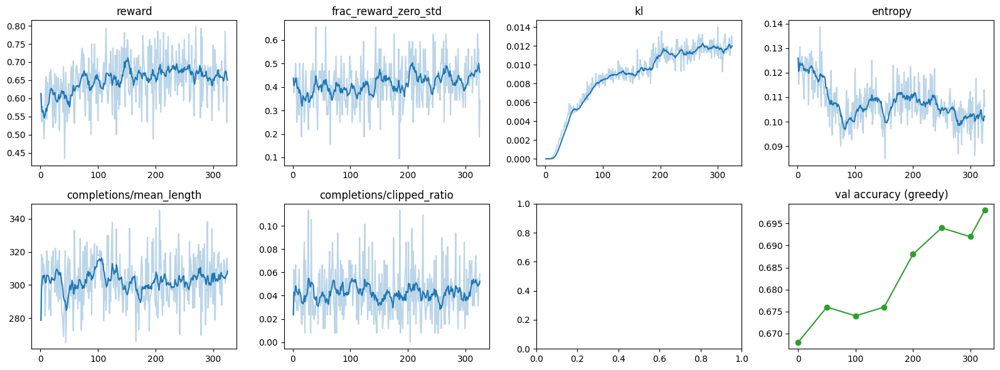

In [9]:
tr = hist[hist["reward"].notna()]
panels = ["reward", "frac_reward_zero_std", "kl", "entropy", "completions/mean_length", "completions/clipped_ratio"]
fig, ax = plt.subplots(2, 4, figsize=(16, 6))
for a, k in zip(ax.flat, [p for p in panels if p in tr]):
    a.plot(tr.step, tr[k], alpha=0.3, c="C0"); a.plot(tr.step, tr[k].rolling(10, min_periods=1).mean(), c="C0"); a.set_title(k)
ax.flat[-1].plot(val_hist.step, val_hist.val_accuracy, "o-", c="C2"); ax.flat[-1].set_title("val accuracy (greedy)")
fig.tight_layout(); fig.savefig(OUT_DIR / "curves.png", dpi=120); plt.show()

## Final eval: val + GSM8K test + SVAMP (best checkpoint, greedy, same code as 01 / 05)

In [10]:
del trainer, model
torch.cuda.empty_cache()
best = AutoModelForCausalLM.from_pretrained(OUT_DIR / "model", dtype=torch.float16).cuda().eval()

metrics = {}
for name in ["gsm8k_val", "gsm8k_test", "svamp_test"]:
    df = pd.read_json(DATA_DIR / f"{name}.jsonl", lines=True, dtype={"gold": str}).head(16 if DEBUG else None)
    df["response"] = generate(best, list(df.question))
    df[["pred", "has_format"]] = df.response.apply(lambda a: pd.Series(extract_pred(a)))
    df["correct"] = [is_correct(p, g) for p, g in zip(df.pred, df.gold)]
    df.to_json(OUT_DIR / f"predictions_{name}.jsonl", orient="records", lines=True)
    metrics[name] = dict(accuracy=round(df.correct.mean(), 4), format_rate=round(df.has_format.mean(), 4),
                         mean_chars=round(df.response.str.len().mean()))
    print(name, metrics[name])

sft = json.loads((SFT_DIR / "metrics.json").read_text())["eval"]
compare = pd.DataFrame({"sft-rft (05)": [sft["val"]["accuracy"], sft["gsm8k"]["accuracy"], sft["svamp"]["accuracy"]],
                        "grpo (06)": [m["accuracy"] for m in metrics.values()]}, index=["val", "gsm8k", "svamp"])
(OUT_DIR / "metrics.json").write_text(json.dumps({"train": summary, "eval": metrics}, indent=2))
compare

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

gsm8k_val {'accuracy': np.float64(0.698), 'format_rate': np.float64(0.966), 'mean_chars': 954}
gsm8k_test {'accuracy': np.float64(0.5436), 'format_rate': np.float64(0.9439), 'mean_chars': 1010}
svamp_test {'accuracy': np.float64(0.632), 'format_rate': np.float64(0.99), 'mean_chars': 792}


,sft-rft (05),grpo (06)
val,0.6660,0.6980
gsm8k,0.4936,0.5436
svamp,0.6190,0.6320
